# Cats vs Dogs Classification Using CNN

This notebook prepares the Oxford-IIIT Pet images, creates binary labels, splits the dataset, and trains a Convolutional Neural Network (CNN). Only the parts needed for correct training and evaluation have been adjusted.


## 1. Imports


In [31]:
import os
import tarfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

## 2. Check the Dataset Folder
If the images have already been extracted, this cell checks that the expected folder exists.


In [32]:
import os

extract_path = "data/images/images"

if os.path.exists(extract_path):
    print("Dataset folder exists!")
else:
    print("Dataset folder not found!")

Dataset folder exists!


## 3. Collect Image Paths
Collect image files only and sort them so that image order remains consistent. Files such as `.mat` are not image files and are excluded.


In [33]:
image_paths = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, file))

image_paths = sorted(image_paths)

print("Total images:", len(image_paths))
print("First 5 files:")

for path in image_paths[:5]:
    print(os.path.basename(path))

Total images: 7360
First 5 files:
Abyssinian_1.jpg
Abyssinian_10.jpg
Abyssinian_100.jpg
Abyssinian_101.jpg
Abyssinian_102.jpg


## 4. Display Sample Images
Display up to 20 images to visually inspect the dataset.


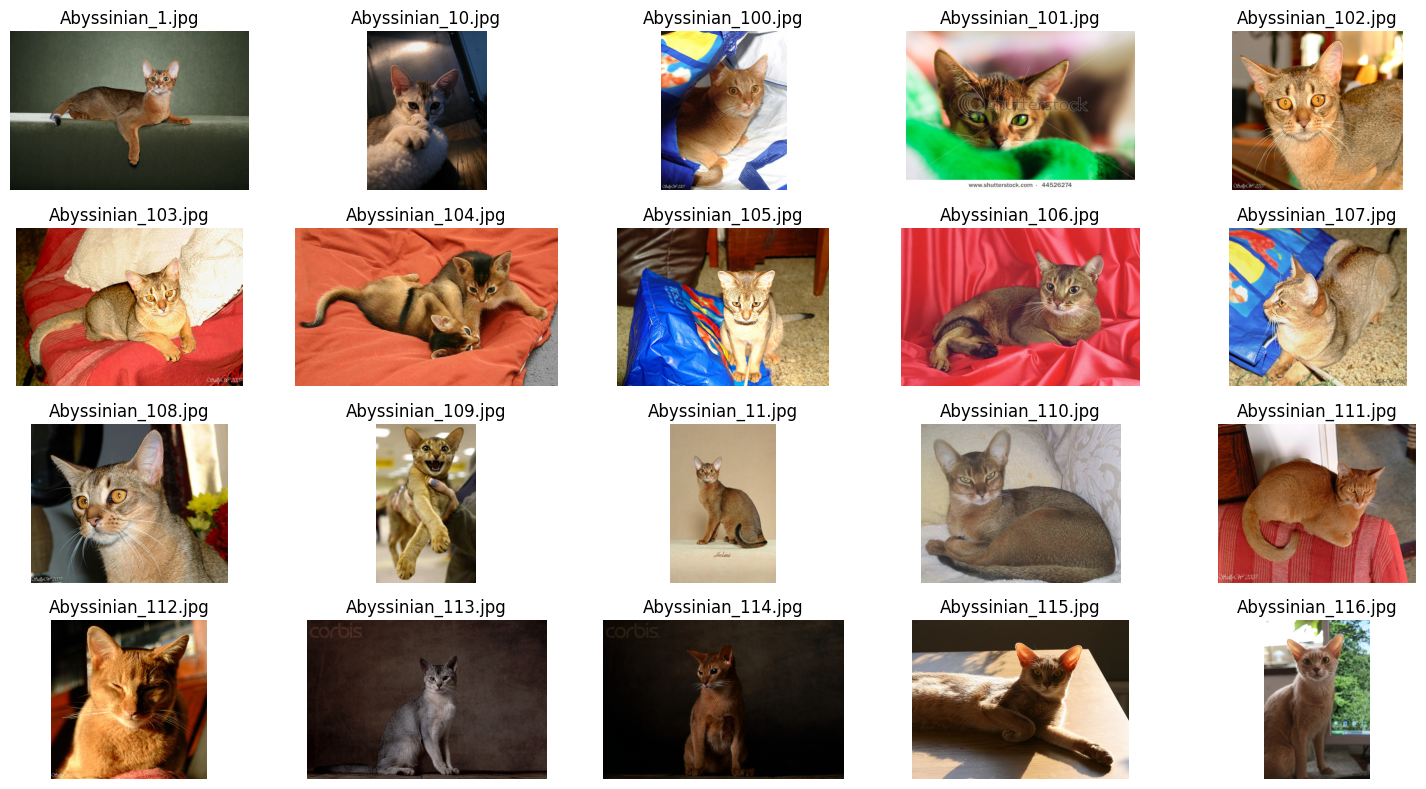

In [34]:
plt.figure(figsize=(15, 8))

for i in range(min(20, len(image_paths))):
    img = Image.open(image_paths[i])

    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(image_paths[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

### Modification 1: Check for Duplicate Filenames

This step checks whether multiple image files have the same filename. It helps identify possible duplicates, but matching filenames alone do not prove that the image contents are identical. The result is used as an initial diagnostic check before training.

In [35]:
from collections import Counter


image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_paths = []

for root, dirs, files in os.walk(extract_path):
    for filename in files:
        if filename.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, filename))

filename_counts = Counter(
    os.path.basename(path).lower()
    for path in image_paths
)

duplicate_names = {
    name: count
    for name, count in filename_counts.items()
    if count > 1
}

print("Total images:", len(image_paths))
print("Unique filenames:", len(filename_counts))
print("Duplicated filenames:", len(duplicate_names))
print("Examples:", list(duplicate_names.items())[:10])

Total images: 7360
Unique filenames: 7360
Duplicated filenames: 0
Examples: []


### Modification 1: Detect Identical Image Files Using MD5

A hash is calculated for each image file using its contents. Files with the same MD5 hash are grouped together as exact duplicate candidates. This is more reliable than comparing filenames because files can have different names but identical contents.

The code reports the number of duplicate groups and the number of extra copies. Review these results before moving any files.

In [36]:

import hashlib
from collections import defaultdict

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

hash_groups = defaultdict(list)

for root, dirs, files in os.walk(extract_path):
    for filename in files:
        if filename.lower().endswith(image_extensions):
            path = os.path.join(root, filename)

            with open(path, "rb") as file:
                file_hash = hashlib.md5(file.read()).hexdigest()

            hash_groups[file_hash].append(path)

duplicate_groups = {
    file_hash: paths
    for file_hash, paths in hash_groups.items()
    if len(paths) > 1
}

print("Total duplicate groups:", len(duplicate_groups))
print("Total extra copies:", sum(len(paths) - 1 for paths in duplicate_groups.values()))

Total duplicate groups: 0
Total extra copies: 0


In [37]:
for file_hash, paths in list(duplicate_groups.items())[:5]:
    print("\nDuplicate group:")
    for path in paths:
        print(path)

### Modification 1: Keep Duplicate Copies in a Backup Folder

This step moves extra copies from each detected duplicate group into a separate backup folder instead of permanently deleting them. The first path in each group is kept in the dataset, while the remaining paths are moved.

**Important:** Run this cell only after reviewing the duplicate groups. After moving files, refresh `image_paths` so it contains only paths that still exist in the dataset folder; otherwise, later image-loading code may try to open moved files.

In [38]:
import shutil

backup_path = os.path.join(os.path.dirname(extract_path), "duplicates_backup")
os.makedirs(backup_path, exist_ok=True)

moved_count = 0

for paths in duplicate_groups.values():
    for duplicate_path in paths[1:]:
        filename = os.path.basename(duplicate_path)
        destination = os.path.join(backup_path, filename)

        counter = 1
        while os.path.exists(destination):
            name, ext = os.path.splitext(filename)
            destination = os.path.join(
                backup_path, f"{name}_{counter}{ext}"
            )
            counter += 1

        shutil.move(duplicate_path, destination)
        moved_count += 1

print("Moved duplicate copies:", moved_count)
print("Backup folder:", backup_path)

Moved duplicate copies: 0
Backup folder: data/images\duplicates_backup


## 5. Resize and Reshape Images
Convert each image to grayscale and resize it to `130 × 130` pixels. Keep track of successfully loaded images so their labels match the images in `X`.


In [39]:
W, H = 130, 130
Allimages = []
valid_paths = []

for path in image_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        img = cv2.resize(img, (W, H))
        img = img.reshape(W, H, 1)
        Allimages.append(img)
        valid_paths.append(path)
    else:
        print("Could not read:", path)

X = np.array(Allimages, dtype=np.uint8)

print("X shape:", X.shape)
print("X data type:", X.dtype)


X shape: (7360, 130, 130, 1)
X data type: uint8


## 6. Create Binary Labels (`y`)
For Oxford-IIIT Pet filenames, cat breed names start with an uppercase letter and dog breed names start with a lowercase letter. Labels are `0 = Cat` and `1 = Dog`. Labels are generated from the same list of successfully loaded images used to create `X`.


In [40]:
y = []

for path in valid_paths:
    filename = os.path.basename(path)
    breed = filename.split("_")[0]

    if breed[0].isupper():
        y.append(0)  # Cat
    else:
        y.append(1)  # Dog

y = np.array(y, dtype=np.int32)

print("X samples:", len(X))
print("y labels:", len(y))
print("Cat labels (0):", np.sum(y == 0))
print("Dog labels (1):", np.sum(y == 1))


X samples: 7360
y labels: 7360
Cat labels (0): 2380
Dog labels (1): 4980


## 7. Check That Images and Labels Match
The number of images must equal the number of labels before training.


In [41]:
assert len(X) == len(y), "X and y have different lengths!"

print("X and y match.")

X and y match.


## 8. Train / Validation / Test Split
Split the dataset into 70% training, 15% validation, and 15% test data. `stratify` keeps the cat/dog proportions approximately consistent across the splits.


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_test, y_test,
    test_size=0.50,
    random_state=42,
    stratify=y_test
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (5888, 130, 130, 1) (5888,)
Validation: (736, 130, 130, 1) (736,)
Testing: (736, 130, 130, 1) (736,)


## 9. Important Notes
- `X` contains the images and `y` contains their binary labels.
- The output layer uses `sigmoid` because this is a binary classification problem with one output neuron.
- Pixel values are scaled to the range `[0, 1]` inside the model.
- A higher accuracy cannot be guaranteed; review the training and validation curves to see whether the model is learning or overfitting.


### Modification: Data Augmentation and Input Scaling

The CNN applies random transformations such as horizontal flipping, small rotations, and zooming during training. This is called **data augmentation** and helps the model learn from varied versions of the training images without manually saving extra image files.

`Rescaling(1.0 / 255)` changes pixel values from the range 0–255 to approximately 0–1. The images are converted to grayscale and resized earlier in the notebook, so the model input shape is `(130, 130, 1)`.

Augmentation should be used to improve generalization, but it does not guarantee higher accuracy.

In [57]:
model = keras.Sequential([
    
    keras.layers.Input(shape=(W, H, 1)),
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.Rescaling(1.0 / 255),
    keras.layers.Conv2D(32, 3, padding="valid", activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Conv2D(64, 3, padding="valid", activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Conv2D(128, 3, padding="valid", activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
])


In [58]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


### Modification: Monitor Training and Validation Accuracy

The training history records the model's accuracy and loss across epochs. Validation data is evaluated during training to help assess how well the model performs on images it does not train on.

The `EarlyStopping` callback monitors `val_accuracy`. If validation accuracy does not improve for five epochs, training stops and the weights from the best validation-accuracy epoch are restored.

A gap between training and validation performance can indicate overfitting. The accuracy plot below compares training accuracy with validation accuracy; a separate loss plot can also be added if required.

In [59]:
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1,
    callbacks=[tf.keras.callbacks.EarlyStopping(
    patience = 5,
    monitor='val_accuracy',
    restore_best_weights=True
    )]
)

val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
print("Validation Accuracy:", val_accuracy)
print("Validation Loss:", val_loss)


Epoch 1/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 45s 231ms/step - accuracy: 0.6792 - loss: 0.6135 - val_accuracy: 0.6916 - val_loss: 0.5640
Epoch 2/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 52s 285ms/step - accuracy: 0.6934 - loss: 0.5650 - val_accuracy: 0.7215 - val_loss: 0.5378
Epoch 3/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 42s 230ms/step - accuracy: 0.7101 - loss: 0.5477 - val_accuracy: 0.7636 - val_loss: 0.5178
Epoch 4/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 45s 247ms/step - accuracy: 0.7294 - loss: 0.5360 - val_accuracy: 0.7364 - val_loss: 0.5096
Epoch 5/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 43s 233ms/step - accuracy: 0.7532 - loss: 0.5072 - val_accuracy: 0.7758 - val_loss: 0.4879
Epoch 6/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 43s 233ms/step - accuracy: 0.7626 - loss: 0.4878 - val_accuracy: 0.7418 - val_loss: 0.4872
Epoch 7/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 42s 229ms/step - accuracy: 0.7733 - loss: 0.4768 - val_accuracy: 0.7935 - val_loss: 0.4480
Epoch 8/25
184/184 ━━━━━━━━━━━━━━━━━━━━ 43s 234ms/step - accuracy: 0.7863 - loss: 0

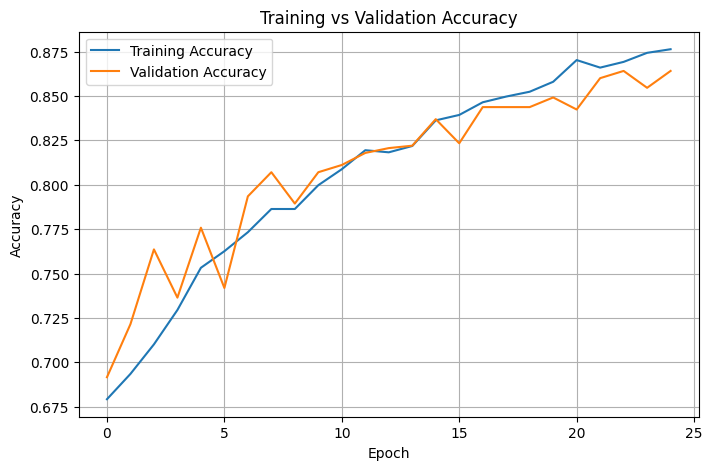

In [60]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## 10. Test Evaluation and Predictions
Evaluate the trained model on the separate test set. The predicted probability is converted to a class using a threshold of `0.5`: `0 = Cat`, `1 = Dog`.

In [64]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

predicted_probabilities = model.predict(X_test[:10], verbose=0).flatten()
predicted_labels = (predicted_probabilities >= 0.5).astype(np.int32)

for i, (probability, predicted_label, true_label) in enumerate(zip(predicted_probabilities, predicted_labels, y_test[:10])):
    predicted_class = "Dog" if predicted_label == 1 else "Cat"
    true_class = "Dog" if true_label == 1 else "Cat"
    print(f"Image {i + 1}: Predicted = {predicted_class} ({probability:.3f}), Actual = {true_class}")


Test Accuracy: 0.8464673757553101
Test Loss: 0.3160126209259033
Image 1: Predicted = Dog (0.817), Actual = Dog
Image 2: Predicted = Dog (1.000), Actual = Dog
Image 3: Predicted = Dog (1.000), Actual = Dog
Image 4: Predicted = Dog (0.984), Actual = Dog
Image 5: Predicted = Dog (1.000), Actual = Dog
Image 6: Predicted = Dog (0.615), Actual = Dog
Image 7: Predicted = Cat (0.459), Actual = Cat
Image 8: Predicted = Dog (1.000), Actual = Dog
Image 9: Predicted = Dog (0.908), Actual = Dog
Image 10: Predicted = Cat (0.092), Actual = Cat


### Modification: Evaluate the Model Beyond Accuracy

The test set is kept separate from the training and validation sets. The model predicts probabilities for the test images, and a threshold of `0.5` converts those probabilities into binary class predictions:

- `0 = Cat`
- `1 = Dog`

These predictions are then used for the classification report, confusion matrix, and baseline comparison below. Keep the class mapping consistent with the labels created earlier in the notebook.

In [65]:


y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).reshape(-1)
y_true = np.array(y_test).reshape(-1)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step


### Classification Report: Precision, Recall, and F1-Score

The classification report summarizes performance for each class:

- **Precision:** Of the images predicted as a class, how many truly belong to that class?
- **Recall:** Of all real images in a class, how many did the model correctly identify?
- **F1-score:** A combined measure of precision and recall.
- **Support:** The number of true test examples in that class.

These metrics help show whether the model performs well for both cats and dogs, rather than relying on accuracy alone.

In [66]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"],
    zero_division=0
))

              precision    recall  f1-score   support

         Cat       0.81      0.69      0.74       238
         Dog       0.86      0.92      0.89       498

    accuracy                           0.85       736
   macro avg       0.83      0.81      0.82       736
weighted avg       0.84      0.85      0.84       736



### Confusion Matrix: Inspect Correct and Incorrect Predictions

The confusion matrix compares the true labels with the predicted labels. With the displayed class order `Cat`, then `Dog`, the diagonal cells represent correct predictions, while the off-diagonal cells represent misclassifications.

Use the matrix to identify whether the model is more likely to confuse cats as dogs or dogs as cats.

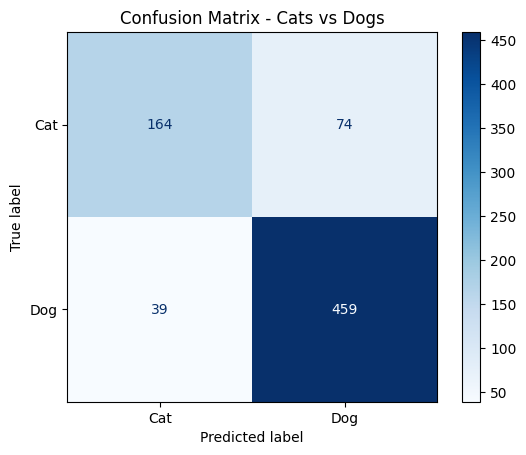

In [67]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Cats vs Dogs")
plt.show()

### Baseline Comparison

A baseline is a simple reference result used to judge whether the trained model adds value. This cell compares test accuracy with a baseline of `67.5%`.

The baseline should match a simple strategy evaluated on the same test set. Before interpreting the result, verify that `67.5%` is appropriate for the class distribution and the chosen baseline; it should not be treated as a universal benchmark.

In [68]:
from sklearn.metrics import accuracy_score

model_accuracy = accuracy_score(y_true, y_pred)

baseline_accuracy = 0.675

print("Model Accuracy:", model_accuracy)
print("Baseline Accuracy:", baseline_accuracy)

if model_accuracy > baseline_accuracy:
    print("The model performs better than the baseline.")
else:
    print("The model does not outperform the baseline.")

Model Accuracy: 0.8464673913043478
Baseline Accuracy: 0.675
The model performs better than the baseline.


### Modification: Find Misclassified Test Images

The code compares the true test labels with the model's predicted labels and records the indices where they differ. The total number of incorrect predictions is printed so that the error analysis can be quantified.

In [69]:


y_true = np.array(y_true).reshape(-1)
y_pred = np.array(y_pred).reshape(-1)

wrong_indices = np.where(y_true != y_pred)[0]

print("Total wrong predictions:", len(wrong_indices))

Total wrong predictions: 113


### Inspect Misclassified Images

The following plot displays up to nine test images that the model classified incorrectly. Each image is labeled with its true class and predicted class.

Inspect the examples to look for patterns such as low image quality, unusual poses, partial visibility, or distracting backgrounds. These are possible explanations only; conclusions should be based on the images actually shown.

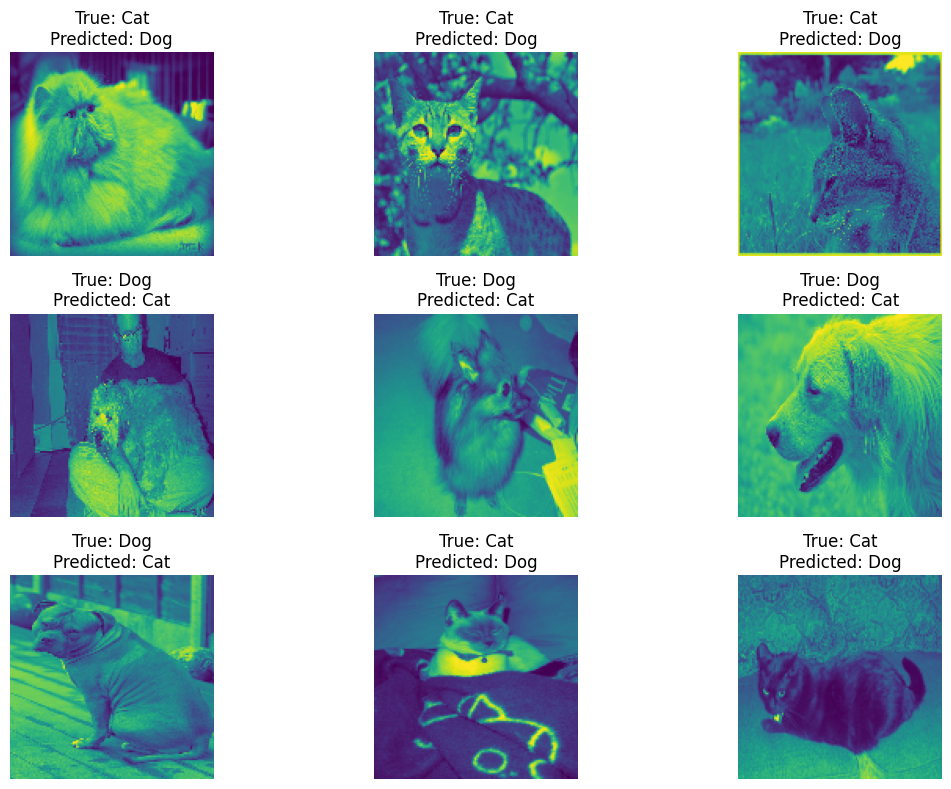

In [70]:


class_names = ["Cat", "Dog"]

plt.figure(figsize=(12, 8))

for i, idx in enumerate(wrong_indices[:9]):
    plt.subplot(3, 3, i + 1)

    image = X_test[idx]

    if image.max() > 1:
        image = image / 255.0

    plt.imshow(image)

    true_label = int(y_true[idx])
    predicted_label = int(y_pred[idx])

    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()